# Praktikum 1  Scraping dan Eksplorasi Data (EDA)

**Sulaiman Faiz Tsaqaib  5054251048**

`https://en.wikipedia.org/wiki/List_of_exoplanets_discovered_in_<tahun>` (10 halaman).

## 1. Scraping Dataset

### 1.1 Sumber data dan etika

`robots.txt` Wikipedia mengizinkan jalur `/wiki/` (diperiksa pada sel di bawah), lisensi CC BY-SA.
10 permintaan dengan jeda 1,5 detik, `timeout` 30 detik, `User-Agent` jujur, hasil di-cache ke CSV.

In [1]:
import re
import time
from pathlib import Path
from urllib.robotparser import RobotFileParser

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from bs4 import BeautifulSoup

DIR_DATA = Path("data")
DIR_GAMBAR = Path("gambar")
DIR_DATA.mkdir(exist_ok=True)
DIR_GAMBAR.mkdir(exist_ok=True)
BERKAS_MENTAH = DIR_DATA / "eksoplanet_mentah.csv"
BERKAS_BERSIH = DIR_DATA / "eksoplanet_bersih.csv"

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 150)

In [2]:
URL_POLA = "https://en.wikipedia.org/wiki/List_of_exoplanets_discovered_in_{tahun}"
USER_AGENT = "DM-PracticeBot/1.0 (Praktikum Data Mining ITS)"
TAHUN = tuple(range(2013, 2023))
KOLOM = ["nama_planet", "massa_mj", "radius_rj", "periode_hari", "sumbu_semimayor_au",
         "suhu_k", "metode_penemuan", "jarak_ly", "massa_bintang_msun",
         "suhu_bintang_k", "keterangan"]


def diizinkan_robots(url: str) -> bool:
    respons = requests.get("https://en.wikipedia.org/robots.txt",
                           headers={"User-Agent": USER_AGENT}, timeout=30)
    if 400 <= respons.status_code < 500:   # RFC 9309: robots.txt tidak ada = boleh diakses
        return True
    parser = RobotFileParser()
    parser.parse(respons.text.splitlines())
    return parser.can_fetch(USER_AGENT, url)


def ambil_html(url: str) -> str:
    respons = requests.get(url, headers={"User-Agent": USER_AGENT}, timeout=30)
    respons.raise_for_status()
    return respons.text


url_contoh = URL_POLA.format(tahun=2016)
print("/wiki/ diizinkan:", diizinkan_robots(url_contoh))
print("/w/     diizinkan:", diizinkan_robots("https://en.wikipedia.org/w/index.php"))

/wiki/ diizinkan: True


/w/     diizinkan: False


### 1.2 Struktur halaman target

Satu tabel `wikitable` per halaman, 11 kolom identik, tanpa sel bersarang.

In [3]:
html_contoh = ambil_html(url_contoh)
tabel_contoh = BeautifulSoup(html_contoh, "html.parser").select_one("table.wikitable")
baris_contoh = tabel_contoh.select("tr")

print("Judul kolom :", [sel.get_text(" ", strip=True) for sel in baris_contoh[0].find_all(["th", "td"])])
print("Jumlah baris:", len(baris_contoh) - 1)
print("Contoh baris:", [td.get_text(" ", strip=True) for td in baris_contoh[1].find_all("td")])

Judul kolom : ['Name', 'Mass ( M J )', 'Radius ( R J )', 'Period (days)', 'Semi-major axis (AU)', 'Temp. ( K ) [ 1 ]', 'Discovery method', 'Distance (ly)', 'Host star mass ( M ☉ )', 'Host star temp. (K)', 'Remarks']
Jumlah baris: 1498
Contoh baris: ['2MASS J2126-8140', '13.3 ± 1.7', '', '', '6900', '1800', 'imaging', '111.4 ± 0.3', '0.53', '3490', '[ 2 ] Ternary star system with red dwarf and (sub-)brown dwarf, found in 2009, found to be planet in 2016']


### 1.3 Fungsi ekstraksi

In [4]:
def urai_tabel(html: str, tahun: int) -> list[dict[str, object]]:
    tabel = BeautifulSoup(html, "html.parser").select_one("table.wikitable")
    hasil = []
    for tr in tabel.select("tr")[1:]:
        sel = [td.get_text(" ", strip=True) for td in tr.find_all(["td", "th"])]
        if len(sel) == len(KOLOM):
            hasil.append(dict(zip(KOLOM, sel), tahun_penemuan=tahun))
    return hasil


uji = pd.DataFrame(urai_tabel(html_contoh, 2016))
assert uji.shape == (1498, 12), uji.shape
uji.head(3)

,nama_planet,massa_mj,radius_rj,periode_hari,sumbu_semimayor_au,suhu_k,metode_penemuan,jarak_ly,massa_bintang_msun,suhu_bintang_k,keterangan,tahun_penemuan
0,2MASS J2126-8140,13.3 ± 1.7,,,6900,1800,imaging,111.4 ± 0.3,0.53,3490,[ 2 ] Ternary star system with red dwarf and (...,2016
1,2MASS J22362452+4751425 b,12.5,,,230,,imaging,240,0.6,4045,member of AB Doradus moving group [ 3 ],2016
2,BD+15 2375 b,1.061,,153.22,0.576,,radial vel.,2520,1.08,4649,[ 4 ],2016


### 1.4 Menjalankan scraping dan menyimpan hasil mentah

In [5]:
def scrape(tahun_daftar: tuple[int, ...] = TAHUN) -> pd.DataFrame:
    semua = []
    for tahun in tahun_daftar:
        url = URL_POLA.format(tahun=tahun)
        assert diizinkan_robots(url), f"robots.txt melarang {url}"
        semua += urai_tabel(ambil_html(url), tahun)
        time.sleep(1.5)
    return pd.DataFrame(semua)[["tahun_penemuan"] + KOLOM]


if BERKAS_MENTAH.exists():
    df_mentah = pd.read_csv(BERKAS_MENTAH)
else:
    df_mentah = scrape()
    df_mentah.to_csv(BERKAS_MENTAH, index=False)

assert len(df_mentah) >= 1500 and df_mentah.shape[1] >= 5
print(f"{df_mentah.shape[0]} baris x {df_mentah.shape[1]} kolom (syarat: >=1500 baris, >=5 fitur)")

4100 baris x 12 kolom (syarat: >=1500 baris, >=5 fitur)


## 2. Import dan Pemahaman Dataset

### 2.1 Head, info, bentuk, dan tipe data

In [6]:
df_mentah.head()

,tahun_penemuan,nama_planet,massa_mj,radius_rj,periode_hari,sumbu_semimayor_au,suhu_k,metode_penemuan,jarak_ly,massa_bintang_msun,suhu_bintang_k,keterangan
0,2013,2MASS J01225093-2439505 b,24.5,NaN,NaN,52,NaN,imaging,120,0.4,3530,[ 2 ]
1,2013,BD+15 2940 b,1.11,NaN,137.48,0.539,NaN,radial vel.,572.2,1.1,4796,[ 3 ]
2,2013,CoRoT-25b,0.27,1.08,4.86069,0.0578,NaN,transit,3300,1.09,6040,[ 4 ]
3,2013,CoRoT-26b,0.52,1.26,4.20474,0.0526,NaN,transit,5400,1.09,5590,[ 4 ]
4,2013,DENIS-P J082303.1-491201 b,28.5,NaN,246.36,0.36,NaN,astrometry,67.7,0.07,2150,[ 5 ]


In [7]:
df_mentah.info()

<class 'pandas.DataFrame'>
RangeIndex: 4100 entries, 0 to 4099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   tahun_penemuan      4100 non-null   int64
 1   nama_planet         4100 non-null   str  
 2   massa_mj            1537 non-null   str  
 3   radius_rj           3472 non-null   str  
 4   periode_hari        3911 non-null   str  
 5   sumbu_semimayor_au  2413 non-null   str  
 6   suhu_k              921 non-null    str  
 7   metode_penemuan     4099 non-null   str  
 8   jarak_ly            3940 non-null   str  
 9   massa_bintang_msun  3720 non-null   str  
 10  suhu_bintang_k      3776 non-null   str  
 11  keterangan          4087 non-null   str  
dtypes: int64(1), str(11)
memory usage: 384.5 KB


In [8]:
df_mentah["tahun_penemuan"].value_counts().sort_index()

tahun_penemuan
2013     149
2014     869
2015     144
2016    1498
2017     152
2018     299
2019     168
2020     256
2021     253
2022     312
Name: count, dtype: int64

### 2.2 Pembersihan dan fitur turunan

`ke_angka()` membuang catatan kaki `[...]`, pemisah ribuan, dan nilai ketidakpastian (`± 1.7`).
Fitur turunan: `radius_bumi` (= `radius_rj` × 11,21) dan `kelas_planet` (ordinal).

In [9]:
ATRIBUT_NUMERIK = ["massa_mj", "radius_rj", "periode_hari", "sumbu_semimayor_au",
                   "suhu_k", "jarak_ly", "massa_bintang_msun", "suhu_bintang_k"]


def ke_angka(teks: object) -> float:
    if not isinstance(teks, str):
        return np.nan
    bersih = re.sub(r"\[[^\]]*\]", "", teks).replace(",", "").replace("−", "-")
    cocok = re.search(r"-?\d+(?:\.\d+)?", bersih)
    return float(cocok.group()) if cocok else np.nan


df = df_mentah.copy()
for kolom in ATRIBUT_NUMERIK:
    df[kolom] = df[kolom].map(ke_angka)

df["metode_penemuan"] = df["metode_penemuan"].str.strip().str.lower()
df["radius_bumi"] = df["radius_rj"] * 11.21   # 1 radius Jupiter = 11,21 radius Bumi
df["kelas_planet"] = pd.cut(df["radius_bumi"], [0, 1.6, 4, 10, np.inf], ordered=True,
                            labels=["Mirip Bumi", "Super-Bumi", "Mirip Neptunus", "Mirip Jupiter"])

pd.DataFrame({"mentah": df_mentah["massa_mj"], "angka": df["massa_mj"]}).head()

,mentah,angka
0,24.5,24.50
1,1.11,1.11
2,0.27,0.27
3,0.52,0.52
4,28.5,28.50


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4100 entries, 0 to 4099
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   tahun_penemuan      4100 non-null   int64   
 1   nama_planet         4100 non-null   str     
 2   massa_mj            1537 non-null   float64 
 3   radius_rj           3472 non-null   float64 
 4   periode_hari        3911 non-null   float64 
 5   sumbu_semimayor_au  2413 non-null   float64 
 6   suhu_k              921 non-null    float64 
 7   metode_penemuan     4099 non-null   str     
 8   jarak_ly            3940 non-null   float64 
 9   massa_bintang_msun  3720 non-null   float64 
 10  suhu_bintang_k      3776 non-null   float64 
 11  keterangan          4087 non-null   str     
 12  radius_bumi         3472 non-null   float64 
 13  kelas_planet        3472 non-null   category
dtypes: category(1), float64(9), int64(1), str(3)
memory usage: 420.7 KB


### 2.3 Identifikasi tipe atribut

| Atribut | Tipe atribut |
|---|---|
| `nama_planet` | Nominal (pengenal unik) |
| `metode_penemuan` | Nominal, 8 kategori |
| `kelas_planet` | **Ordinal**, 4 tingkat menurut ukuran |
| `tahun_penemuan` | Numerik **diskrit** |
| `massa_mj`, `radius_rj`, `radius_bumi`, `periode_hari`, `sumbu_semimayor_au`, `suhu_k`, `jarak_ly`, `massa_bintang_msun`, `suhu_bintang_k` | Numerik **kontinu**, skala rasio |
| `keterangan` | Teks bebas |

In [11]:
ATRIBUT_KATEGORIKAL = ["metode_penemuan", "kelas_planet", "tahun_penemuan"]

pd.DataFrame({"tipe_pandas": df.dtypes.astype("string"), "nilai_unik": df.nunique()})

,tipe_pandas,nilai_unik
tahun_penemuan,int64,10
nama_planet,str,4093
massa_mj,float64,1001
radius_rj,float64,878
periode_hari,float64,3897
sumbu_semimayor_au,float64,1471
suhu_k,float64,726
metode_penemuan,str,8
jarak_ly,float64,1506
massa_bintang_msun,float64,516


## 3. Analisis Statistik dan Kualitas Data

### 3.1 Statistik deskriptif atribut numerik

In [12]:
statistik = df[ATRIBUT_NUMERIK].describe().T
statistik["median"] = df[ATRIBUT_NUMERIK].median()
statistik["modus"] = df[ATRIBUT_NUMERIK].mode().iloc[0]
statistik["skewness"] = df[ATRIBUT_NUMERIK].skew()
statistik.round(3)

,count,mean,std,min,25%,50%,75%,max,median,modus,skewness
massa_mj,1537.0,1.768,3.849,0.000,0.030,0.390,1.600,5.920000e+01,0.390,0.015,5.159
radius_rj,3472.0,0.353,0.387,0.001,0.139,0.205,0.302,3.400000e+00,0.205,0.178,2.150
periode_hari,3911.0,106530.316,6398131.344,0.086,4.199,10.115,27.044,4.000000e+08,10.115,0.605,62.478
sumbu_semimayor_au,2413.0,12.753,234.530,0.003,0.051,0.092,0.248,7.506000e+03,0.092,0.048,26.585
suhu_k,921.0,1031.419,568.875,39.000,598.000,936.000,1411.000,4.700000e+03,936.000,1800.000,1.118
jarak_ly,3940.0,2498.746,3769.326,4.200,615.500,1650.000,2910.000,3.000000e+04,1650.000,2600.000,4.161
massa_bintang_msun,3720.0,0.927,0.418,0.009,0.770,0.940,1.080,9.750000e+00,0.940,0.940,8.164
suhu_bintang_k,3776.0,5361.301,1164.994,0.550,4931.000,5557.500,5901.250,4.000000e+04,5557.500,5770.000,10.515


### 3.2 Frekuensi atribut kategorikal

In [13]:
for kolom in ATRIBUT_KATEGORIKAL:
    frekuensi = df[kolom].value_counts(dropna=False)
    print(f"=== {kolom} ===")
    print(pd.DataFrame({"frekuensi": frekuensi,
                        "persen": (frekuensi / len(df) * 100).round(2)}).to_string(), "\n")

=== metode_penemuan ===
                               frekuensi  persen
metode_penemuan                                 
transit                             3418   83.37
radial vel.                          439   10.71
microlensing                         175    4.27
imaging                               32    0.78
timing                                28    0.68
orbital brightness modulation          4    0.10
astrometry                             2    0.05
astrometry + imaging                   1    0.02
NaN                                    1    0.02 

=== kelas_planet ===
                frekuensi  persen
kelas_planet                     
Super-Bumi           1816   44.29
Mirip Bumi            924   22.54
NaN                   628   15.32
Mirip Jupiter         456   11.12
Mirip Neptunus        276    6.73 

=== tahun_penemuan ===
                frekuensi  persen
tahun_penemuan                   
2016                 1498   36.54
2014                  869   21.20
2022           

### 3.3 Identifikasi nilai yang hilang

In [14]:
print("Total sel kosong:", int(df.isna().sum().sum()))

pd.DataFrame({"jumlah_hilang": df.isna().sum(),
              "persen": (df.isna().mean() * 100).round(2)}).sort_values("jumlah_hilang", ascending=False)

Total sel kosong: 10380


,jumlah_hilang,persen
suhu_k,3179,77.54
massa_mj,2563,62.51
sumbu_semimayor_au,1687,41.15
radius_rj,628,15.32
kelas_planet,628,15.32
radius_bumi,628,15.32
massa_bintang_msun,380,9.27
suhu_bintang_k,324,7.90
periode_hari,189,4.61
jarak_ly,160,3.90


In [15]:
# proporsi nilai yang TIDAK diketahui, per metode penemuan
kosong = df.groupby("metode_penemuan")[["radius_rj", "massa_mj"]].apply(lambda g: g.isna().mean()).round(3)
kosong["jumlah_planet"] = df["metode_penemuan"].value_counts()
kosong.sort_values("jumlah_planet", ascending=False)

,radius_rj,massa_mj,jumlah_planet
metode_penemuan,,,
transit,0.002,0.748,3418
radial vel.,0.904,0.009,439
microlensing,1.000,0.000,175
imaging,0.656,0.031,32
timing,0.714,0.071,28
orbital brightness modulation,0.750,0.000,4
astrometry,1.000,0.000,2
astrometry + imaging,1.000,0.000,1


### 3.4 Deteksi outlier dan pemeriksaan validitas

Aturan IQR (Tukey) dan skor-Z `|z| > 3`; kolom `skewness_log10` menguji apakah nilai ekstrem hanya
efek skala.

In [16]:
def ringkas_outlier(kolom: str) -> dict[str, float]:
    nilai = df[kolom].dropna()
    q1, q3 = nilai.quantile([0.25, 0.75])
    bawah, atas = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    iqr_outlier = (nilai < bawah) | (nilai > atas)
    skor_z = (nilai - nilai.mean()) / nilai.std()
    return {
        "n": len(nilai),
        "batas_bawah": round(bawah, 3),
        "batas_atas": round(atas, 3),
        "outlier_IQR": int(iqr_outlier.sum()),
        "persen_IQR": round(iqr_outlier.mean() * 100, 2),
        "outlier_Z>3": int((skor_z.abs() > 3).sum()),
        "skewness": round(nilai.skew(), 2),
        "skewness_log10": round(np.log10(nilai[nilai > 0]).skew(), 2),
    }


pd.DataFrame({kolom: ringkas_outlier(kolom) for kolom in ATRIBUT_NUMERIK}).T

,n,batas_bawah,batas_atas,outlier_IQR,persen_IQR,outlier_Z>3,skewness,skewness_log10
massa_mj,1537.0,-2.325,3.955,193.0,12.56,37.0,5.16,-0.14
radius_rj,3472.0,-0.105,0.546,578.0,16.65,66.0,2.15,0.72
periode_hari,3911.0,-30.067,61.310,570.0,14.57,1.0,62.48,1.62
sumbu_semimayor_au,2413.0,-0.244,0.543,451.0,18.69,6.0,26.58,1.74
suhu_k,921.0,-621.500,2630.500,6.0,0.65,5.0,1.12,-0.68
jarak_ly,3940.0,-2826.250,6351.750,187.0,4.75,128.0,4.16,-0.85
massa_bintang_msun,3720.0,0.305,1.545,246.0,6.61,16.0,8.16,-2.36
suhu_bintang_k,3776.0,3475.625,7356.625,165.0,4.37,12.0,10.52,-18.58


In [17]:
print("Periode orbit terpanjang:")
print(df.nlargest(3, "periode_hari")[["nama_planet", "periode_hari", "sumbu_semimayor_au", "metode_penemuan"]].to_string(index=False))

print("\nSuhu bintang < 2.000 K (nilai mentah dari Wikipedia):")
print(df_mentah.loc[df["suhu_bintang_k"] < 2000, ["nama_planet", "suhu_bintang_k", "radius_rj"]].to_string(index=False))

print("\nSuhu bintang > 10.000 K:")
print(df.loc[df["suhu_bintang_k"] > 10000, ["nama_planet", "suhu_bintang_k"]].to_string(index=False))

print("\nNama planet ganda     :", int(df["nama_planet"].duplicated().sum()))
print("Nilai numerik negatif :", int((df[ATRIBUT_NUMERIK] < 0).sum().sum()))

Periode orbit terpanjang:
     nama_planet  periode_hari  sumbu_semimayor_au metode_penemuan
     COCONUTS-2b   400000000.0              7506.0         imaging
CFHTWIR-Oph 98 b     8040000.0               200.0         imaging
 VHS 1256-1257 b     6200000.0               360.0         imaging

Suhu bintang < 2.000 K (nilai mentah dari Wikipedia):
         nama_planet    suhu_bintang_k            radius_rj
            HATS-70b 1.08 +0.16 − 0.14 1.384 +0.079 − 0.074
OGLE-2017-BLG-1522Lb  1500 +1000 − 500                  NaN
        Gliese 685 b       0.55 ± 0.06                  NaN
           WASP-183b     0.784 ± 0.038    1.47 +0.94 − 0.33

Suhu bintang > 10.000 K:
    nama_planet  suhu_bintang_k
    HD 100546 b         10500.0
    Kepler-451b         29564.0
        KELT-9b         10170.0
NSVS 14256825 b         40000.0
  Mu2 Scorpii b         21900.0
  Mu2 Scorpii c         21900.0

Nama planet ganda     : 7
Nilai numerik negatif : 0


### 3.5 Penanganan nilai hilang dan outlier

| Temuan | Keputusan | Alasan |
|---|---|---|
| `massa_mj`, `radius_rj`, `suhu_k` kosong | Tidak diimputasi | Keterbatasan metode ukur, bukan kesalahan catat |
| `metode_penemuan` kosong (1 baris) | Isi `"tidak diketahui"` | Baris tetap terhitung |
| Suhu bintang di bawah 2.000 K (4 baris) | Jadikan `NaN` | Melanggar batas fisika, kolom sumber tertukar |
| Nama planet duplikat (7 baris) | Hapus, simpan yang pertama | Satu planet satu baris |
| Outlier periode, sumbu, massa | Pertahankan + kolom log₁₀ | Planet nyata; log menormalkan tanpa buang data |

In [18]:
KOLOM_LOG = ["massa_mj", "radius_rj", "periode_hari", "sumbu_semimayor_au", "jarak_ly"]

sebelum = len(df)
df.loc[df["suhu_bintang_k"] < 2000, "suhu_bintang_k"] = np.nan
df["metode_penemuan"] = df["metode_penemuan"].fillna("tidak diketahui")
df = df.drop_duplicates(subset="nama_planet").reset_index(drop=True)

for kolom in KOLOM_LOG:
    df[f"log_{kolom}"] = np.log10(df[kolom].where(df[kolom] > 0))

df.to_csv(BERKAS_BERSIH, index=False)
print(f"Baris: {sebelum} -> {len(df)} (buang duplikat nama planet)")
print(pd.DataFrame({"skew_asli": df[KOLOM_LOG].skew().to_numpy(),
                    "skew_log10": df[[f"log_{k}" for k in KOLOM_LOG]].skew().to_numpy()},
                   index=KOLOM_LOG).round(2).to_string())

Baris: 4100 -> 4093 (buang duplikat nama planet)


                    skew_asli  skew_log10
massa_mj                 5.15       -0.14
radius_rj                2.16        0.72
periode_hari            62.43        1.62
sumbu_semimayor_au      26.55        1.74
jarak_ly                 4.17       -0.85


## 4. Visualisasi Data

In [19]:
LABEL = {
    "massa_mj": "Massa planet (M Jupiter)",
    "radius_rj": "Radius planet (R Jupiter)",
    "periode_hari": "Periode orbit (hari)",
    "sumbu_semimayor_au": "Sumbu semimayor (AU)",
    "jarak_ly": "Jarak dari Bumi (tahun cahaya)",
    "suhu_bintang_k": "Suhu bintang induk (K)",
}


def simpan(fig: plt.Figure, nama: str) -> None:
    fig.tight_layout()
    fig.savefig(DIR_GAMBAR / f"{nama}.png", bbox_inches="tight")

### 4.1 Univariat — numerik, skala asli

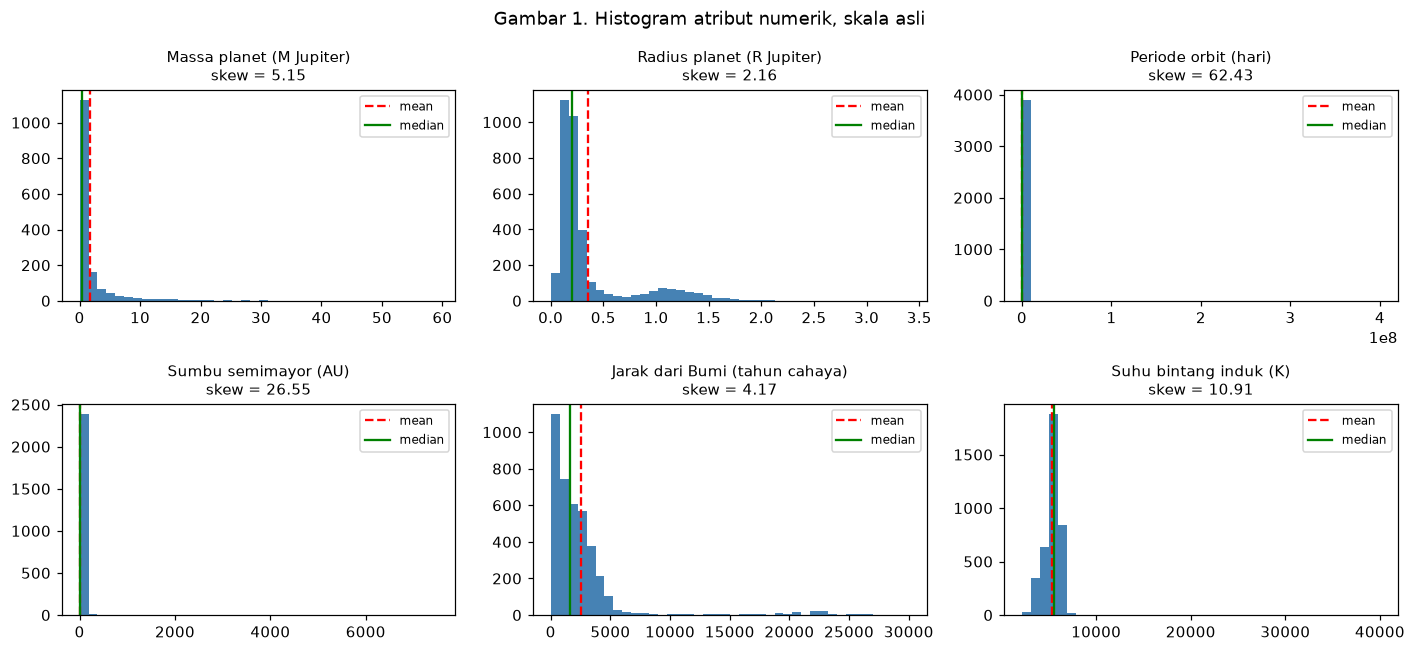

In [20]:
fig, sumbu = plt.subplots(2, 3, figsize=(13, 6))
for ax, kolom in zip(sumbu.ravel(), LABEL):
    ax.hist(df[kolom].dropna(), bins=40, color="steelblue")
    ax.axvline(df[kolom].mean(), color="red", ls="--", label="mean")
    ax.axvline(df[kolom].median(), color="green", label="median")
    ax.set_title(f"{LABEL[kolom]}\nskew = {df[kolom].skew():.2f}", fontsize=10)
    ax.legend(fontsize=8)

fig.suptitle("Gambar 1. Histogram atribut numerik, skala asli")
simpan(fig, "01_histogram_skala_asli")
plt.show()

### 4.2 Univariat — numerik, skala logaritmik

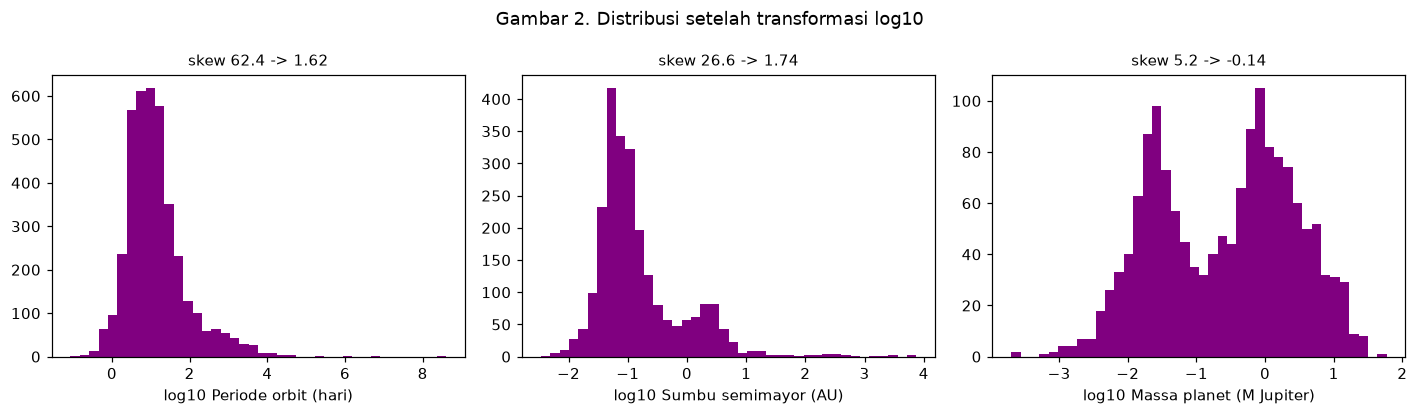

In [21]:
fig, sumbu = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, kolom in zip(sumbu, ["periode_hari", "sumbu_semimayor_au", "massa_mj"]):
    nilai = df[f"log_{kolom}"].dropna()
    ax.hist(nilai, bins=40, color="purple")
    ax.set_xlabel(f"log10 {LABEL[kolom]}")
    ax.set_title(f"skew {df[kolom].skew():.1f} -> {nilai.skew():.2f}", fontsize=10)

fig.suptitle("Gambar 2. Distribusi setelah transformasi log10")
simpan(fig, "02_histogram_log")
plt.show()

### 4.3 Univariat — atribut kategorikal

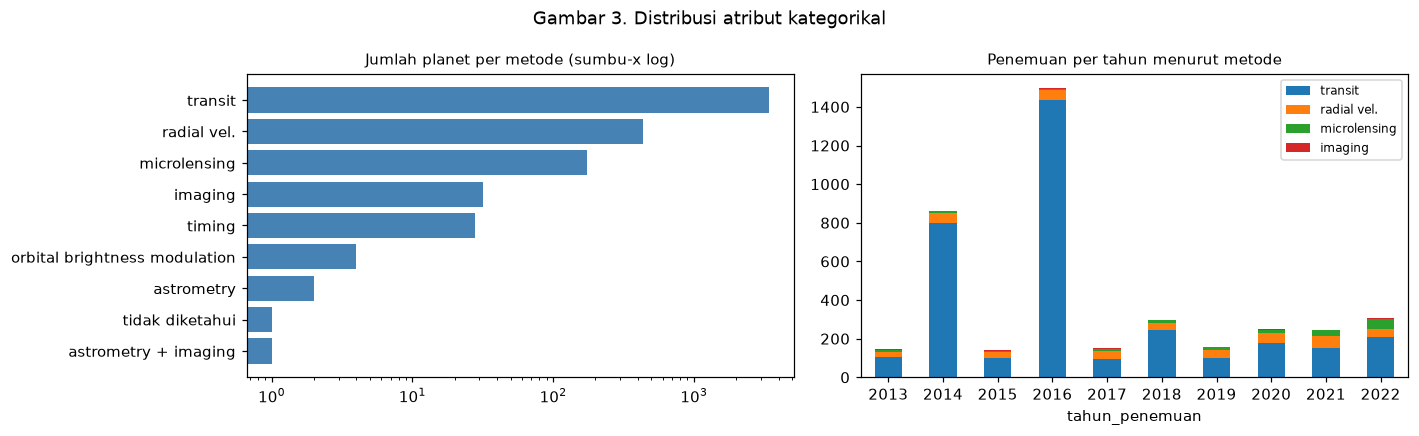

In [22]:
fig, sumbu = plt.subplots(1, 2, figsize=(13, 4))

metode = df["metode_penemuan"].value_counts().sort_values()
sumbu[0].barh(metode.index, metode.to_numpy(), color="steelblue")
sumbu[0].set_xscale("log")
sumbu[0].set_title("Jumlah planet per metode (sumbu-x log)", fontsize=10)

pd.crosstab(df["tahun_penemuan"], df["metode_penemuan"])[metode.index[:-5:-1]].plot(
    kind="bar", stacked=True, ax=sumbu[1], rot=0)
sumbu[1].set_title("Penemuan per tahun menurut metode", fontsize=10)
sumbu[1].legend(fontsize=8)

fig.suptitle("Gambar 3. Distribusi atribut kategorikal")
simpan(fig, "03_bar_kategorikal")
plt.show()

### 4.4 Bivariat — hubungan antar atribut numerik

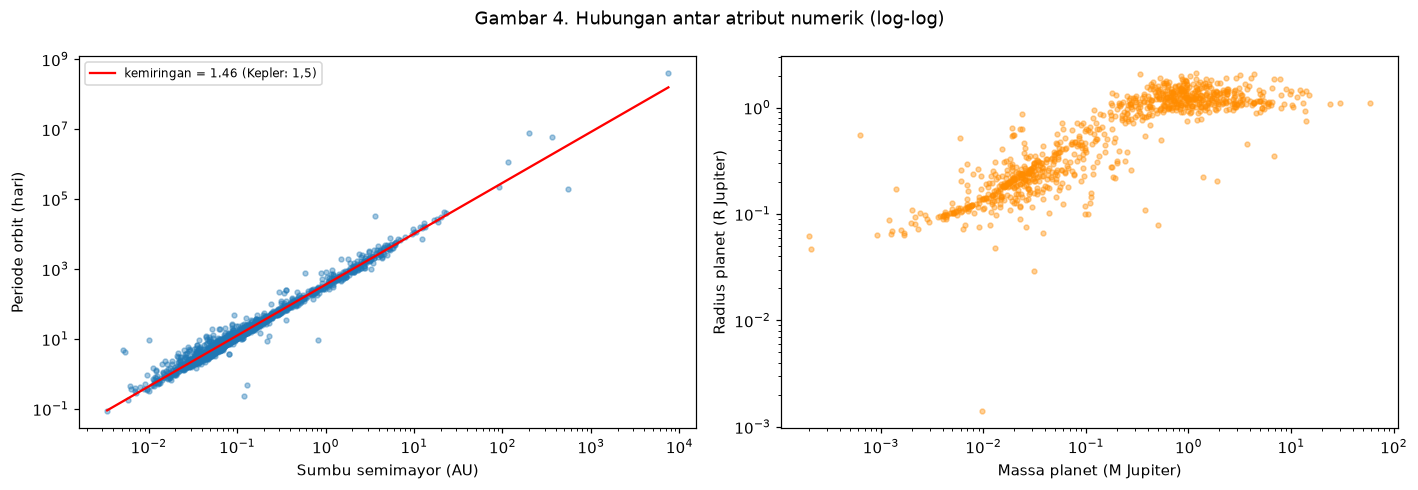

Kepler       : n=2226, r=0.988
Massa-radius : n=914, r(log)=0.877, r(asli)=0.303


In [23]:
fig, sumbu = plt.subplots(1, 2, figsize=(13, 4.5))

kepler = df.dropna(subset=["log_sumbu_semimayor_au", "log_periode_hari"])
kemiringan, potongan = np.polyfit(kepler["log_sumbu_semimayor_au"], kepler["log_periode_hari"], 1)
garis_x = np.linspace(kepler["log_sumbu_semimayor_au"].min(), kepler["log_sumbu_semimayor_au"].max(), 50)
sumbu[0].scatter(kepler["sumbu_semimayor_au"], kepler["periode_hari"], s=10, alpha=0.4)
sumbu[0].plot(10 ** garis_x, 10 ** (kemiringan * garis_x + potongan), color="red",
              label=f"kemiringan = {kemiringan:.2f} (Kepler: 1,5)")
sumbu[0].set(xscale="log", yscale="log", xlabel=LABEL["sumbu_semimayor_au"], ylabel=LABEL["periode_hari"])
sumbu[0].legend(fontsize=8)

massa_radius = df.dropna(subset=["log_massa_mj", "log_radius_rj"])
sumbu[1].scatter(massa_radius["massa_mj"], massa_radius["radius_rj"], s=10, alpha=0.4, color="darkorange")
sumbu[1].set(xscale="log", yscale="log", xlabel=LABEL["massa_mj"], ylabel=LABEL["radius_rj"])

fig.suptitle("Gambar 4. Hubungan antar atribut numerik (log-log)")
simpan(fig, "04_scatter_hubungan")
plt.show()

print(f"Kepler       : n={len(kepler)}, r={kepler['log_sumbu_semimayor_au'].corr(kepler['log_periode_hari']):.3f}")
print(f"Massa-radius : n={len(massa_radius)}, r(log)={massa_radius['log_massa_mj'].corr(massa_radius['log_radius_rj']):.3f}, "
      f"r(asli)={df['massa_mj'].corr(df['radius_rj']):.3f}")

### 4.5 Bivariat — antar kategori dan matriks korelasi

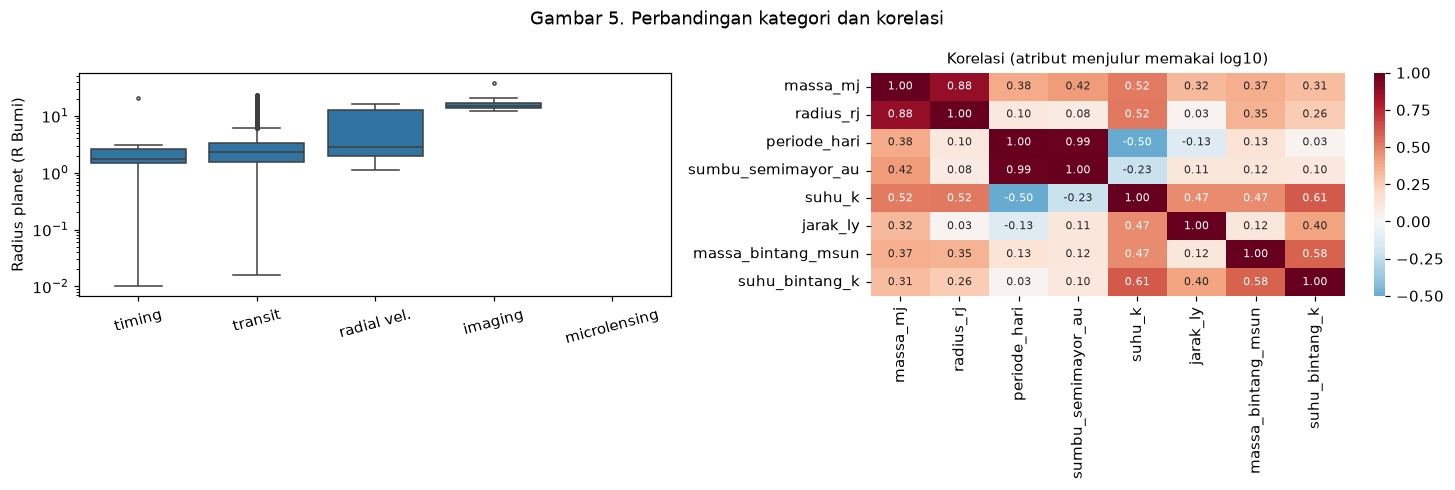

                               count  median
metode_penemuan                             
astrometry                         0     NaN
astrometry + imaging               0     NaN
imaging                           11   14.69
microlensing                       0     NaN
orbital brightness modulation      1   15.25
radial vel.                       42    2.87
tidak diketahui                    0     NaN
timing                             8    1.73
transit                         3405    2.29


In [24]:
fig, sumbu = plt.subplots(1, 2, figsize=(13.5, 4.5))

subset = df[df["metode_penemuan"].isin(df["metode_penemuan"].value_counts().index[:5])]
urutan = subset.groupby("metode_penemuan")["radius_bumi"].median().sort_values().index
sns.boxplot(data=subset, x="metode_penemuan", y="radius_bumi", order=urutan, ax=sumbu[0], fliersize=2)
sumbu[0].set(yscale="log", xlabel="", ylabel="Radius planet (R Bumi)")
sumbu[0].tick_params(axis="x", rotation=15)

matriks = df[[f"log_{k}" if f"log_{k}" in df.columns else k for k in ATRIBUT_NUMERIK]].corr()
matriks.index = matriks.columns = ATRIBUT_NUMERIK
sns.heatmap(matriks, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=sumbu[1], annot_kws={"size": 7})
sumbu[1].set_title("Korelasi (atribut menjulur memakai log10)", fontsize=10)

fig.suptitle("Gambar 5. Perbandingan kategori dan korelasi")
simpan(fig, "05_boxplot_korelasi")
plt.show()

print(df.groupby("metode_penemuan")["radius_bumi"].agg(["count", "median"]).round(2).to_string())

### 4.6 Ringkasan temuan visual

1. Distribusi log-normal: skewness `periode_hari` 62,5 jadi 1,62 setelah log₁₀ — pakai median dan
   skala log, dan jangan telan aturan IQR mentah-mentah. Massa ternyata bimodal.
2. Transit 3.413 planet vs astrometri 2 — bentuk dataset ditentukan jadwal rilis Kepler (2014, 2016).
3. Hukum Ketiga Kepler muncul kembali: `log T` vs `log a` lurus, r = 0,988, kemiringan 1,46 (teori 1,5).
   Sekaligus uji kewajaran bahwa scraping dan konversi angka benar.
4. Massa–radius r = 0,877 (log) vs 0,303 (asli), tetapi bengkok: radius mendatar di ~1 R_J.
   Hanya 914 dari 4.093 planet (22%) punya kedua atribut.
5. Bias seleksi: median radius planet hasil imaging 14,7 R_Bumi vs transit 2,3 R_Bumi.
6. `periode_hari` dan `sumbu_semimayor_au` berkorelasi 0,99 — redundan untuk pemodelan.


## 5. Laporan Analisis

Uraian lengkap ada di `LAPORAN.md`.

In [25]:
print(f"Baris x kolom (mentah)      : {df_mentah.shape[0]} x {df_mentah.shape[1]}")
print(f"Baris x kolom (bersih)      : {df.shape[0]} x {df.shape[1]}")
print(f"Total sel kosong            : {int(df_mentah.isna().sum().sum())}")
print(f"Metode terbanyak            : {df['metode_penemuan'].mode().iloc[0]} "
      f"({df['metode_penemuan'].value_counts(normalize=True).iloc[0] * 100:.1f}%)")
print(f"Skew periode asli -> log10  : {df['periode_hari'].skew():.2f} -> {df['log_periode_hari'].skew():.2f}")
print(f"r log(sumbu)-log(periode)   : {df['log_sumbu_semimayor_au'].corr(df['log_periode_hari']):.3f} "
      f"(kemiringan {kemiringan:.2f}, Kepler 1,5)")
print(f"r log(massa)-log(radius)    : {df['log_massa_mj'].corr(df['log_radius_rj']):.3f}")
print(f"Median radius (R Bumi)      : imaging {df.loc[df['metode_penemuan'] == 'imaging', 'radius_bumi'].median():.1f} "
      f"vs transit {df.loc[df['metode_penemuan'] == 'transit', 'radius_bumi'].median():.1f}")

Baris x kolom (mentah)      : 4100 x 12
Baris x kolom (bersih)      : 4093 x 19
Total sel kosong            : 9124
Metode terbanyak            : transit (83.4%)
Skew periode asli -> log10  : 62.43 -> 1.62
r log(sumbu)-log(periode)   : 0.988 (kemiringan 1.46, Kepler 1,5)
r log(massa)-log(radius)    : 0.877
Median radius (R Bumi)      : imaging 14.7 vs transit 2.3


## Referensi

- Wikipedia — *Lists of exoplanets*, <https://en.wikipedia.org/wiki/Lists_of_exoplanets> (CC BY-SA)
- NASA Exoplanet Archive, <https://exoplanetarchive.ipac.caltech.edu/>
- Dokumentasi [Beautiful Soup](https://beautiful-soup-4.readthedocs.io/en/latest/), [Requests](https://requests.readthedocs.io/en/stable/)
- Tukey, J. W., *Exploratory Data Analysis*, Addison-Wesley, 1977
- RFC 9309 — *Robots Exclusion Protocol*, <https://www.rfc-editor.org/rfc/rfc9309.html>